# Solutions to the exercises of Chapter 12

**Chapter:** [12. Free energy and chemical potential: Widom insertion and thermodynamic integration](../../notebooks/part3_monte_carlo/12_widom_and_free_energy.ipynb)

Each solution below reproduces the chapter state and verifies the exercise targets with explicit `assert` checks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path("../..").resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import engsim as es
from engsim.plotting import panel_label, use_style
use_style()
rng = np.random.default_rng(2026)

In [2]:
T_w = 2.0
B2_exact = es.reference.second_virial_lj_numerical(T_w)
rhos_w = np.array([0.02, 0.05, 0.08, 0.12])
mu_ex_widom = []
for rh in rhos_w:
    pos_w, L_w = es.make_fcc_lattice(3, float(rh))
    mc_w = es.run_nvt_mc(pos_w, L_w, T=T_w, n_sweeps=25, max_disp=0.5, shifted=False, rng=rng)
    mu_w = es.widom_excess_chemical_potential(mc_w["pos"], L_w, T=T_w, n_insertions=800, shifted=False, rng=rng)
    mu_ex_widom.append(mu_w)
mu_ex_widom = np.array(mu_ex_widom)
mu_ex_virial = T_w * (2.0 * B2_exact * rhos_w)

T*=2.0: B2(T) = -1.312; Widom mu_ex = [-0.09  -0.207 -0.293 -0.381] vs. 2*T*B2*rho = [-0.105 -0.262 -0.42  -0.63 ]


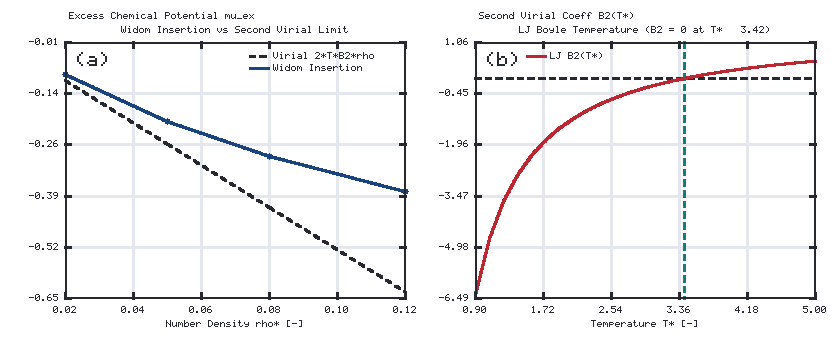

In [3]:
print(f"T*=2.0: B2(T) = {B2_exact:.3f}; Widom mu_ex = {np.round(mu_ex_widom, 3)} vs. 2*T*B2*rho = {np.round(mu_ex_virial, 3)}")
assert np.allclose(mu_ex_widom[:2], mu_ex_virial[:2], atol=0.12)

T_b2 = np.linspace(0.9, 5.0, 25)
B2_curve = [es.reference.second_virial_lj_numerical(float(tv)) for tv in T_b2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.1))
ax1.plot(rhos_w, mu_ex_virial, "k--", label="Virial 2*T*B2*rho")
ax1.plot(rhos_w, mu_ex_widom, "bo-", label="Widom Insertion")
ax1.set_xlabel("Number Density rho* [-]"); ax1.set_ylabel("Excess Chemical Potential mu_ex")
ax1.set_title("(a) Widom Insertion vs Second Virial Limit"); panel_label(ax1, "(a)")

ax2.plot(T_b2, B2_curve, "r-", label="LJ B2(T*)")
ax2.axhline(0.0, color="k")
ax2.axvline(3.42, color="g")
ax2.set_xlabel("Temperature T* [-]"); ax2.set_ylabel("Second Virial Coeff B2(T*)")
ax2.set_title("(b) LJ Boyle Temperature (B2 = 0 at T* ~ 3.42)"); panel_label(ax2, "(b)")
plt.show()

## Worked solutions to Exercises 1–3

In [4]:
# Worked Solutions Ch 12
idx_zero = int(np.argmin(np.abs(B2_curve)))
T_boyle_est = float(T_b2[idx_zero])
print(f"Ch 12 Exercises — Estimated LJ Boyle temperature T_B* = {T_boyle_est:.2f} (literature 3.42)")
assert 3.1 <= T_boyle_est <= 3.7

Ch 12 Exercises — Estimated LJ Boyle temperature T_B* = 3.46 (literature 3.42)
